In [1]:
!pip install python-Levenshtein -q

from PIL import Image, ImageDraw
import numpy as np
import random
import string

VOCAB = ['milk', 'wheat', 'soy', 'peanut', 'egg', 'sugar', 'salt', 'water',
         'oil', 'corn', 'rice', 'butter', 'cream', 'nut', 'gluten', 'yeast']
CHARS = sorted(set(' '.join(VOCAB)))  # unique characters used
CHAR_TO_IDX = {c: i+1 for i, c in enumerate(CHARS)}  # 0 reserved for CTC blank
IDX_TO_CHAR = {i+1: c for i, c in enumerate(CHARS)}
NUM_CLASSES = len(CHARS) + 1  # +1 for blank

def generate_label_image(text, size=(200, 32)):
    img = Image.new('L', size, color=255)
    draw = ImageDraw.Draw(img)
    draw.text((5, 8), text, fill=0)
    return np.array(img, dtype=np.float32) / 255.0

def text_to_indices(text):
    return [CHAR_TO_IDX[c] for c in text]

N = 8000
images, texts = [], []
for _ in range(N):
    text = ' '.join(random.choices(VOCAB, k=random.randint(2, 4)))
    text = text[:24]  # cap length so it fits the image width
    images.append(generate_label_image(text))
    texts.append(text)

print(f"Generated {len(images)} samples. Vocab size: {NUM_CLASSES}")
print(f"Example: '{texts[0]}'")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 157.4/157.4 kB 4.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.2/3.2 MB 51.9 MB/s eta 0:00:00
Generated 8000 samples. Vocab size: 21
Example: 'yeast nut cream'


In [2]:
import torch
from torch.utils.data import Dataset, DataLoader

class LabelDataset(Dataset):
    def __init__(self, images, texts):
        self.images = images
        self.texts = texts
    def __len__(self):
        return len(self.images)
    def __getitem__(self, idx):
        img = torch.tensor(self.images[idx]).unsqueeze(0)  # (1, H, W)
        label = torch.tensor(text_to_indices(self.texts[idx]), dtype=torch.long)
        return img, label, len(label)

def collate_fn(batch):
    imgs, labels, lengths = zip(*batch)
    imgs = torch.stack(imgs)
    labels_cat = torch.cat(labels)
    lengths = torch.tensor(lengths, dtype=torch.long)
    return imgs, labels_cat, lengths

split = int(0.85 * N)
train_ds = LabelDataset(images[:split], texts[:split])
val_ds = LabelDataset(images[split:], texts[split:])
train_loader = DataLoader(train_ds, batch_size=32, shuffle=True, collate_fn=collate_fn)
val_loader = DataLoader(val_ds, batch_size=32, shuffle=False, collate_fn=collate_fn)

In [3]:
import torch.nn as nn

class CRNN(nn.Module):
    def __init__(self, num_classes, hidden=64):
        super().__init__()
        self.cnn = nn.Sequential(
            nn.Conv2d(1, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),   # H/2
            nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),  # H/4
            nn.Conv2d(64, 128, 3, padding=1), nn.ReLU(), nn.MaxPool2d((2,1)),  # H/8, W same
        )
        self.rnn = nn.LSTM(128 * 4, hidden, bidirectional=True, batch_first=True, num_layers=2)
        self.fc = nn.Linear(hidden * 2, num_classes)

    def forward(self, x):
        conv = self.cnn(x)  # (B, C, H', W')
        b, c, h, w = conv.size()
        conv = conv.permute(0, 3, 1, 2).reshape(b, w, c * h)  # (B, W, C*H) — width = time steps
        rnn_out, _ = self.rnn(conv)
        out = self.fc(rnn_out)  # (B, W, num_classes)
        return out.log_softmax(2)

model = CRNN(NUM_CLASSES)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model = model.to(device)
print(f"Using device: {device}")

Using device: cuda


In [4]:
ctc_loss = nn.CTCLoss(blank=0, zero_infinity=True)
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

train_losses = []
model.train()
for epoch in range(15):
    epoch_loss = 0
    for imgs, labels, label_lengths in train_loader:
        imgs, labels = imgs.to(device), labels.to(device)
        optimizer.zero_grad()
        preds = model(imgs)  # (B, W, num_classes)
        preds = preds.permute(1, 0, 2)  # CTC wants (T, B, C)
        input_lengths = torch.full((imgs.size(0),), preds.size(0), dtype=torch.long)
        loss = ctc_loss(preds, labels, input_lengths, label_lengths)
        loss.backward()
        optimizer.step()
        epoch_loss += loss.item()
    avg_loss = epoch_loss / len(train_loader)
    train_losses.append(avg_loss)
    print(f"Epoch {epoch+1}: loss={avg_loss:.4f}")

Epoch 1: loss=3.1263
Epoch 2: loss=2.8820
Epoch 3: loss=2.7113
Epoch 4: loss=2.5430
Epoch 5: loss=2.3379
Epoch 6: loss=2.0415
Epoch 7: loss=1.7035
Epoch 8: loss=1.2232
Epoch 9: loss=0.7757
Epoch 10: loss=0.3688
Epoch 11: loss=0.1385
Epoch 12: loss=0.0756
Epoch 13: loss=0.0494
Epoch 14: loss=0.0329
Epoch 15: loss=0.0259


In [5]:
import Levenshtein

def ctc_decode(preds):
    # preds: (W, num_classes) log-probs for one sample
    pred_idx = preds.argmax(dim=1).cpu().numpy()
    decoded = []
    prev = -1
    for idx in pred_idx:
        if idx != 0 and idx != prev:  # collapse repeats, skip blank
            decoded.append(IDX_TO_CHAR[idx])
        prev = idx
    return ''.join(decoded)

model.eval()
total_cer = 0
examples = []
with torch.no_grad():
    for imgs, labels, label_lengths in val_loader:
        imgs = imgs.to(device)
        preds = model(imgs)  # (B, W, num_classes)
        offset = 0
        for i in range(imgs.size(0)):
            true_text = ''.join(IDX_TO_CHAR[idx.item()] for idx in labels[offset:offset+label_lengths[i]])
            offset += label_lengths[i]
            pred_text = ctc_decode(preds[i])
            cer = Levenshtein.distance(true_text, pred_text) / max(len(true_text), 1)
            total_cer += cer
            if len(examples) < 5:
                examples.append((true_text, pred_text))

avg_cer = total_cer / len(val_ds)
print(f"Validation CER: {avg_cer:.4f}")
print("\nSample predictions:")
for true, pred in examples:
    print(f"  True: '{true}' | Predicted: '{pred}'")

Validation CER: 0.0012

Sample predictions:
  True: 'nut cream wheat' | Predicted: 'nut cream wheat'
  True: 'egg sugar' | Predicted: 'egg sugar'
  True: 'cream rice egg oil' | Predicted: 'cream rice egg oil'
  True: 'corn peanut sugar butter' | Predicted: 'corn peanut sugar butter'
  True: 'gluten oil peanut salt' | Predicted: 'gluten oil peanut salt'


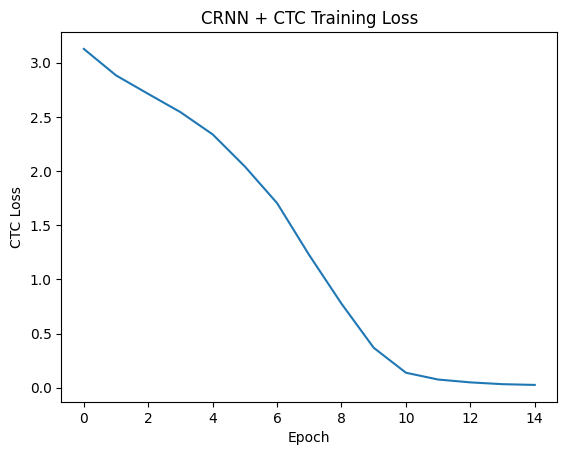

In [6]:
import matplotlib.pyplot as plt
plt.plot(train_losses)
plt.title('CRNN + CTC Training Loss')
plt.xlabel('Epoch'); plt.ylabel('CTC Loss')
plt.savefig('ocr_training_loss.png', dpi=150)
plt.show()

In [7]:
import json
torch.save(model.state_dict(), 'crnn_ocr.pt')
json.dump(IDX_TO_CHAR, open('ocr_vocab.json', 'w'))